##
Red Neuronal

## Librerias y Configuración

In [6]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, 
    f1_score, roc_auc_score, classification_report, 
    confusion_matrix, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:.4f}".format)

In [8]:
#Plantilla de construcción de conjunto de pruebas y testeo

df = pd.read_csv("../data/df_final.csv")

numeric_features = [
    "age", "baseline_bmi", "baseline_charlson_comorbidity_index",
    "systolic_bp_mmhg", "diastolic_bp_mmhg", "heart_rate_bpm",
    "respiratory_rate_bpm", "temperature_celsius", "spo2_percent",
    "blood_glucose_mg_dl", "serum_creatinine_mg_dl", "hemoglobin_g_dl",
    "white_blood_cell_count", "length_of_stay_days", "icu_days",
    "news2_acuity_score", "n_meds", "n_high_risk_meds", "total_drug_cost"
]

categoric_features = [
    "gender", "race_ethnicity", "socioeconomic_tier", "residential_zone",
    "smoker_status", "blood_group", "marital_status", "primary_insurance_provider",
    "encounter_type", "admission_urgency", "department",
    "disease_category", "disease_severity", "procedure_complexity"
]

y = df["readmission_30d"].copy()
X = df[numeric_features + categoric_features]

print(f"\nX shape: {X.shape}")
print(f"y shape: {y.shape}")



#Particionmiento de datos en train y test, con estratificación para mantener la proporción de clases en ambos conjuntos
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,          
    random_state=42,         
    stratify=y              
)


#Preprocesamiento de daots
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categoric_features)
    ],
    remainder="drop"
)



X shape: (13214, 33)
y shape: (13214,)


In [9]:
#Evaluación del modelo
X_train_p = preprocessor.fit_transform(X_train)
X_test_p = preprocessor.transform(X_test)

red = MLPClassifier(
    hidden_layer_sizes=(32, 16),  # dos capas ocultas
    activation="relu",
    solver="adam",                # variante del descenso de gradiente
    learning_rate_init=0.001,     # la "tasa de aprendizaje" de las diapositivas
    alpha=1e-3,                   # regularización L2
    early_stopping=True,          # frena cuando deja de mejorar en validación
    max_iter=500,
    random_state=42
)

#Entrenamiento del modelo
red.fit(X_train_p, y_train)


,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(32, ...)"
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.001
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",500
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"early_stopping early_stopping: bool, default=FalseWhether to use early stopping to terminate training when validationscore is not improving. If set to True, it will automatically setaside ``validation_fraction`` of training data as validation andterminate training when validation score is not improving by at least``tol`` for ``n_iter_no_change`` consecutive epochs. The split isstratified, except in a multilabel setting.If early stopping is False, then the training stops when the trainingloss does not improve by more than ``tol`` for ``n_iter_no_change``consecutive passes over the training set.Only effective when solver='sgd' or 'adam'.",True
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating t

In [10]:
#Evaluacion del modelo

y_pred_nn = red.predict(X_test_p)
y_proba_nn = red.predict_proba(X_test_p)[:, 1]

print("\n--- Red Neuronal (MLP) ---")
print(f"Accuracy : {accuracy_score(y_test, y_pred_nn):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_nn, zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_nn, zero_division=0):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred_nn, zero_division=0):.4f}")
print(f"AUC-ROC  : {roc_auc_score(y_test, y_proba_nn):.4f}")
print(classification_report(y_test, y_pred_nn,
      target_names=["No Readmisión (0)", "Readmisión (1)"], zero_division=0))



--- Red Neuronal (MLP) ---
Accuracy : 0.7022
Precision: 0.5927
Recall   : 0.3150
F1-score : 0.4114
AUC-ROC  : 0.7096
                   precision    recall  f1-score   support

No Readmisión (0)       0.73      0.89      0.80      1770
   Readmisión (1)       0.59      0.32      0.41       873

         accuracy                           0.70      2643
        macro avg       0.66      0.60      0.61      2643
     weighted avg       0.68      0.70      0.67      2643



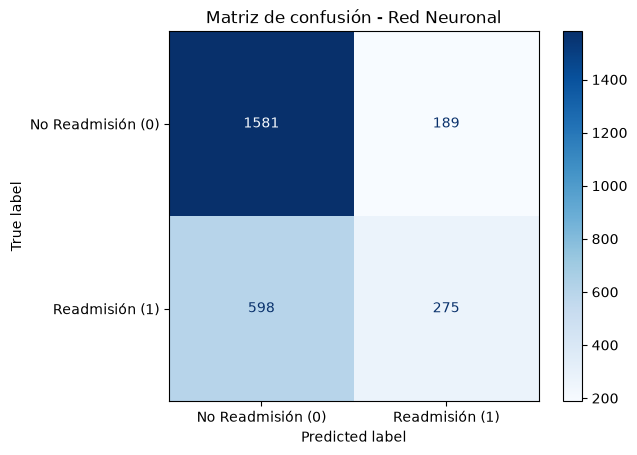

In [11]:
#Matriz de confusion 
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_nn),
    display_labels=["No Readmisión (0)", "Readmisión (1)"]).plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión - Red Neuronal")
plt.show()